# Study 02 — Genetic Algorithm (GA)

Exploratory study notebook: before wiring GA into the full experiment system, we check that it works,
learn how its hyper-parameters behave on our tuning problem, and see how it copes with every controller and plant.

**Questions**
1. Does the implementation actually optimise? (benchmark functions with known optimum)
2. Which hyper-parameters matter for controller tuning, and how much?
3. With a fixed evaluation budget, is it better to have a big population or many generations?
4. How well does it tune each controller on each plant — and where does it fail?

All runs use the project's own simulator, metrics and objective through
`smart_control.experiments.runner.run_single_experiment`. Only `numpy`, `matplotlib` and `control` are used.
⏱ Full run: about 5 minutes on a laptop.

## The algorithm

**Idea.** A population of real-coded chromosomes evolves by
**tournament selection** → **simulated binary crossover (SBX)** → **polynomial mutation**, with the best
individual(s) copied unchanged (**elitism**).

* SBX creates two children around the parents; the distribution index $\eta_c$ controls how close
  (large $\eta_c$ → children near parents).
* Polynomial mutation perturbs each gene with probability `mutation_rate` (default $1/n$).
* Larger tournaments mean stronger selection pressure.

Hyper-parameters to study: **tournament size**, **mutation rate**, and the SBX index **η_c**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from study_utils import *          # project import, runners, benchmarks, plots
from smart_control.optimizers.genetic_algorithm import GeneticAlgorithm

KEY, COLOR = "GA", OPT_COLORS["GA"]
print("Implementation defaults:")
for k, v in GeneticAlgorithm().default_settings().items():
    print(f"  {k:22s} {v}")

Implementation defaults:
  population_size        30
  max_iterations         100
  random_seed            42
  selection              tournament
  tournament_size        2
  crossover_rate         0.9
  eta_c                  20.0
  mutation_rate          None
  eta_m                  20.0
  elite_count            1
  tolerance              None


## 1. Sanity check on benchmark functions

Before tuning controllers, make sure GA minimises functions whose optimum we know (all have minimum 0):
**Sphere** (one smooth bowl), **Rastrigin** (a grid of local minima) and **Rosenbrock** (a curved, narrow valley),
in 2, 5 and 10 dimensions, with ≈500 evaluations and 3 seeds.

In [2]:
bench = benchmark_runs(GeneticAlgorithm, budget(KEY, 20, 24))
benchmark_table(bench)

Function     dim  best f (mean of seeds)  worst seed
Sphere         2               0.0002748   0.0007615
Sphere         5                  0.2485      0.3901
Sphere        10                    16.7       22.77
Rastrigin      2                  0.4455      0.9993
Rastrigin      5                   11.92       17.24
Rastrigin     10                   64.57       71.79
Rosenbrock     2                 0.08529      0.2557
Rosenbrock     5                   7.928       9.333
Rosenbrock    10                     314       533.6


Where does it sample? Each dot is one objective evaluation on 2-D Rastrigin.

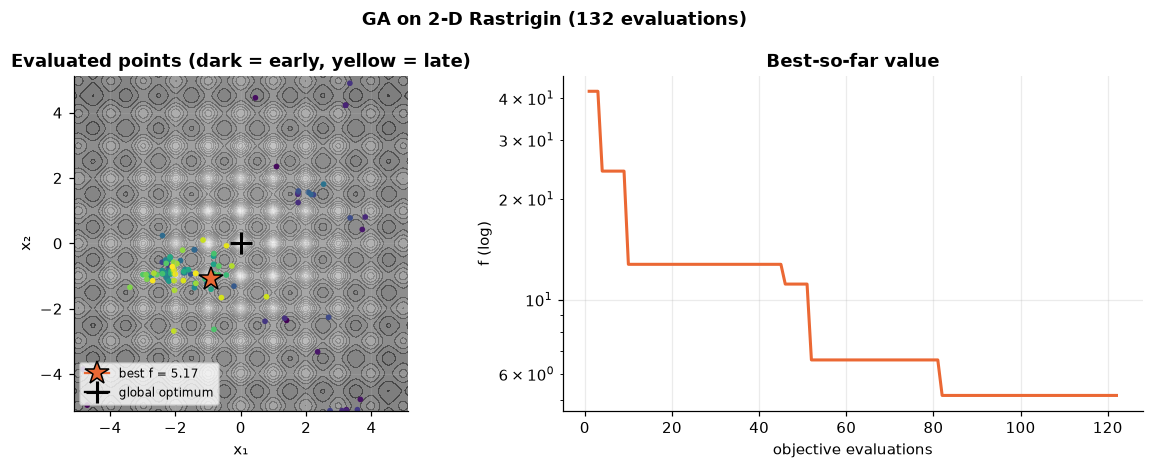

In [3]:
plot_search(GeneticAlgorithm, budget(KEY, 12, 10), COLOR, title="GA on 2-D Rastrigin (132 evaluations)")

## 2. Hyper-parameter study

**Test case:** PID on the 3rd-order plant — cheap to simulate, and sensitive enough to show differences.
Budget ≈60 evaluations, 3 seeds per setting; the heat-map shows **mean J** (± std), best setting outlined.

### 2a. tournament size × mutation rate (None = 1/n)

27 runs in 41 s


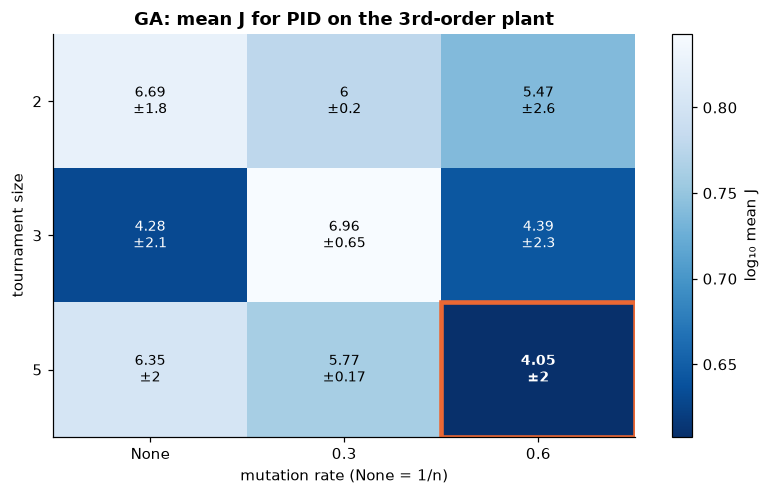

Best: tournament size = 5, mutation rate (None = 1/n) = 0.6  ->  mean J = 4.053
Worst/best ratio: 1.7x


In [4]:
ROWS, COLS = [2, 3, 5], [None, 0.3, 0.6]
mean, std = sweep2d(GeneticAlgorithm, budget(KEY, 10, 5), 'tournament_size', ROWS, 'mutation_rate', COLS)
i, j = sweep_heatmap(mean, ROWS, COLS, "tournament size", "mutation rate (None = 1/n)",
                     "GA: mean J for PID on the 3rd-order plant", std=std)
print(f"Best: tournament size = {ROWS[i]}, mutation rate (None = 1/n) = {COLS[j]}  ->  mean J = {mean[i, j]:.4g}")
print(f"Worst/best ratio: {mean.max() / mean.min():.1f}x")

### 2b. SBX η_c

Small η_c spreads children far from the parents (exploration); large η_c keeps them close (exploitation).

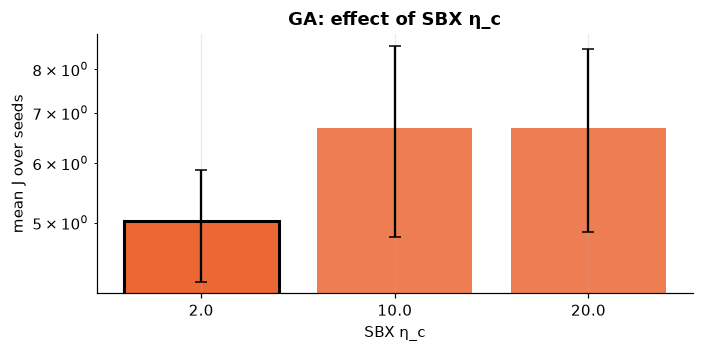

SBX η_c =    2.0   mean J = 5.031 ± 0.85
SBX η_c =   10.0   mean J = 6.693 ± 1.9
SBX η_c =   20.0   mean J = 6.686 ± 1.8


In [5]:
VALUES = [2.0, 10.0, 20.0]
m1, s1 = sweep1d(GeneticAlgorithm, budget(KEY, 10, 5), 'eta_c', VALUES)
plot_sweep1d(VALUES, m1, s1, "SBX η_c", COLOR, "GA: effect of SBX η_c")
for v, m, sd in zip(VALUES, m1, s1):
    print(f"SBX η_c = {v!s:>6}   mean J = {m:.4g} ± {sd:.2g}")

## 3. Population vs generations at a fixed budget

Every split below costs exactly **120 evaluations** (P × (1 + G)). Few large generations explore more;
many small generations exploit more. PID on the 3rd-order plant, 3 seeds.

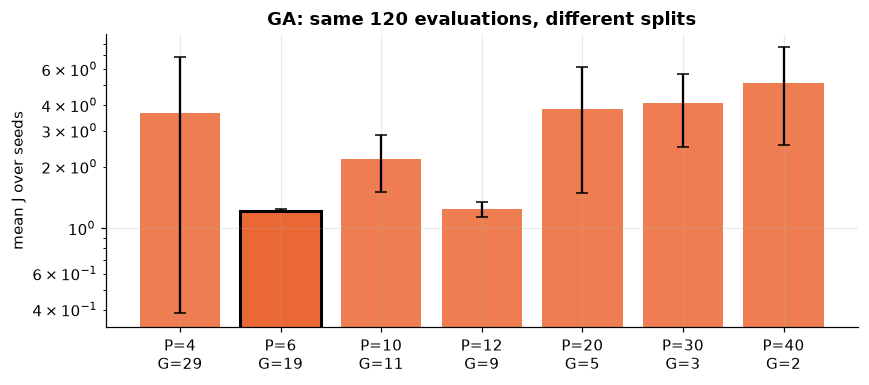

P =  4, G = 29   mean J = 3.642 ± 3.3
P =  6, G = 19   mean J = 1.22 ± 0.02
P = 10, G = 11   mean J = 2.18 ± 0.68
P = 12, G =  9   mean J = 1.24 ± 0.11
P = 20, G =  5   mean J = 3.813 ± 2.3
P = 30, G =  3   mean J = 4.084 ± 1.6
P = 40, G =  2   mean J = 5.108 ± 2.6


In [6]:
SPLITS = [(4, 29), (6, 19), (10, 11), (12, 9), (20, 5), (30, 3), (40, 2)]
means, stds = [], []
for p, g in SPLITS:
    js = [run(GeneticAlgorithm, "PID", "third_order", budget(KEY, p, g), seed)["best_fitness"] for seed in (42, 43, 44)]
    means.append(np.mean(js)); stds.append(np.std(js))
plot_budget_split(SPLITS, means, stds, COLOR, "GA: same 120 evaluations, different splits")
for (p, g), m, sd in zip(SPLITS, means, stds):
    print(f"P = {p:2d}, G = {g:2d}   mean J = {m:.4g} ± {sd:.2g}")

## 4. Every controller on every plant

The real question: **how does GA do on the actual tuning problems?**

* Budget: population 10 × 5 generations ⇒ **≈60 objective evaluations per run** (the *Extended* budget used in the final system).
* Hyper-parameters: the **implementation defaults** (so these numbers match the final system), not the sweep winners above.
* 3 independent seeds (42, 43, 44) per cell → 4 controllers × 3 plants × 3 seeds = 36 runs.
* Fuzzy runs dominate the runtime (25-rule inference at every simulation step).

In [7]:
records = run_matrix(GeneticAlgorithm, list(CONTROLLERS), PLANT_NAMES, budget(KEY, 10, 5), seeds=(42, 43, 44))

PID             2nd order seed 42  J =    0.5675  IAE =    0.35  settled = yes  (1.6 s)


PID             2nd order seed 43  J =     1.592  IAE =    0.31  settled = yes  (1.9 s)


PID             2nd order seed 44  J =    0.6593  IAE =   0.284  settled = yes  (2.3 s)


PID             3rd order seed 42  J =     6.667  IAE =    0.66  settled = yes  (1.9 s)


PID             3rd order seed 43  J =     4.456  IAE =   0.662  settled = yes  (1.6 s)


PID             3rd order seed 44  J =     8.935  IAE =    1.06  settled = yes  (1.3 s)


... (26 outputs left out)

GP Controller   3rd order seed 44  J =      32.3  IAE =    7.92  settled = no   (1.7 s)


GP Controller   4th order seed 42  J =        33  IAE =    8.66  settled = no   (1.2 s)


GP Controller   4th order seed 43  J =        33  IAE =    8.66  settled = no   (1.2 s)


GP Controller   4th order seed 44  J =        33  IAE =    8.66  settled = no   (1.3 s)

36 runs in 309 s


### Results table
J is mean ± std over seeds; the metric columns are from the best seed.

In [8]:
summary_table(records)

Controller      Plant        J mean    ± std  settled     IAE  Ts (s)  Tr (s)    OS %      Ess
----------------------------------------------------------------------------------------------
PID             2nd order    0.9396    0.463     3/3    0.35    0.72   0.443       0  0.00167
PID             3rd order     6.686     1.83     3/3   0.662    5.42   0.461    4.33 0.000805
PID             4th order     294.7      314     0/3    8.37       —     1.3    68.9    0.284
Neural Network  2nd order     32.11     4.13     0/3    3.45       —    1.82       0    0.139
Neural Network  3rd order        36     6.64     1/3    6.07    19.9   0.531    28.8    0.162
Neural Network  4th order     61.15     17.5     0/3    20.5       —       —       0     1.38
Fuzzy           2nd order    0.9759    0.141     3/3   0.535    1.02    0.81       0  0.00077
Fuzzy           3rd order     1.694    0.378     3/3   0.663    1.53   0.691   0.317   0.0067
Fuzzy           4th order     49.94     27.8     0/3    5.

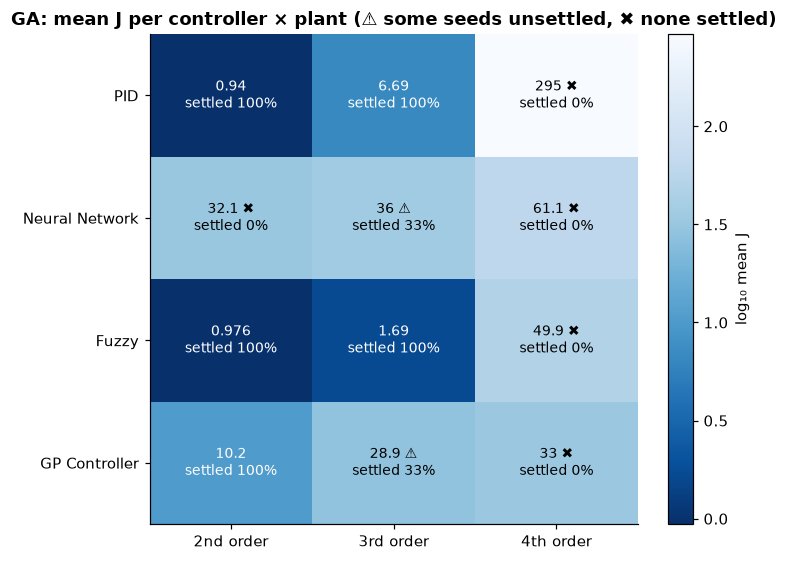

In [9]:
plot_matrix_heatmap(records, "GA: mean J per controller × plant (⚠ some seeds unsettled, ✖ none settled)")

### Step responses (best seed of each cell)

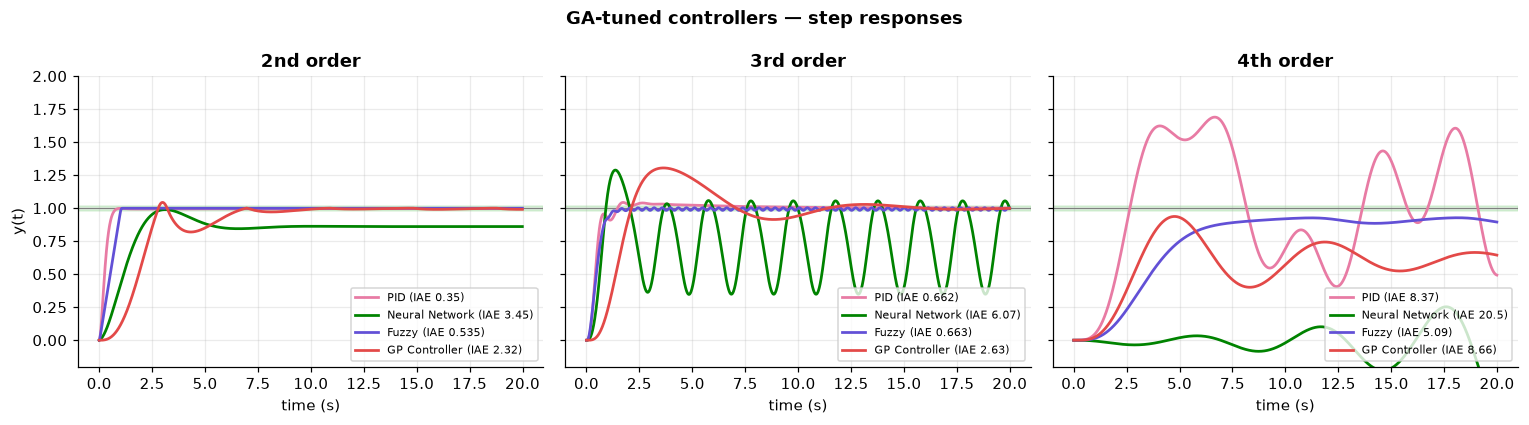

In [10]:
plot_step_grid(records, "GA-tuned controllers — step responses")

### Convergence
One line per seed; solid = 2nd, dashed = 3rd, dotted = 4th order.

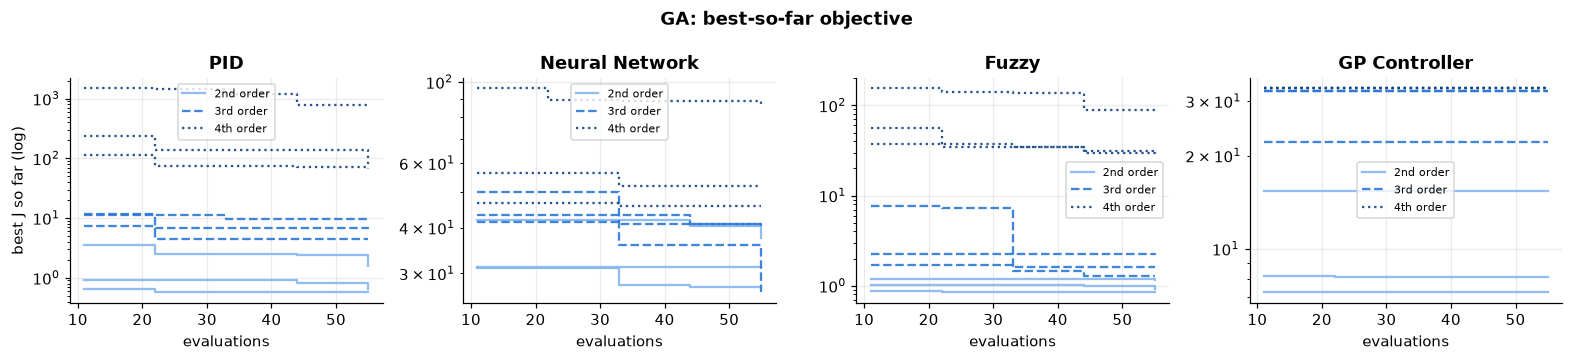

In [11]:
plot_convergence_grid(records, COLOR, "GA: best-so-far objective")

### Control effort on the 3rd-order plant
A good response is not enough if the actuator has to work unreasonably hard.

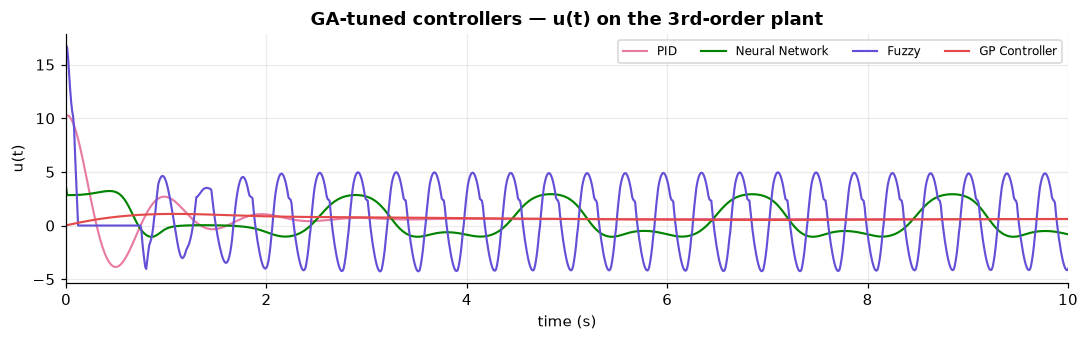

In [12]:
plot_control_effort(records, "third_order", "GA-tuned controllers — u(t) on the 3rd-order plant")

## Takeaways

**1. Weakest on the benchmarks in higher dimensions.** Fine in 2-D (Sphere ≈ 3e-4, Rastrigin ≈ 0.45), but in 10-D it lags clearly (Sphere ≈ 16.7 vs 3.0 for DE and 0.06 for PSO; Rosenbrock ≈ 314). SBX children stay close to their parents, so progress per generation is slow when many genes must move together.

**2. Fairly insensitive to its hyper-parameters (1.7× spread).** Best: **tournament size 5 with mutation rate 0.6** (J ≈ 4.05). Stronger selection plus much more mutation than the default 1/n helps under a tiny budget. The SBX index points the same way: **η_c = 2 (wide, exploratory children) beat the default 20** (J 5.0 vs 6.7).

**3. Budget split:** the clearest result of all four studies — **small populations with many generations win** (P = 6, G = 19: J ≈ 1.22 ± 0.02; P = 12, G = 9: J ≈ 1.24), while large populations are 3–4× worse (P = 40, G = 2: J ≈ 5.1). GA needs generations for selection to do its work.

**4. On the real problems (≈60 evals, defaults):**
- **PID 2nd order and Fuzzy 2nd/3rd order are tuned well** (all seeds settle; Fuzzy 3rd order J ≈ 1.7).
- **PID on the 3rd-order plant is clearly worse than with DE/PSO/SA** (J ≈ 6.7 vs ≈ 1.2–3.3), and **PID on the 4th-order plant fails on every seed** (J ≈ 295, seed 44 diverges to J ≈ 739).
- **Fuzzy on the 4th-order plant also fails on every seed** — the only optimiser where that happens.
- Neural network: 1/9 runs settle. GP controller: same degenerate J = 33 on the 4th-order plant.

**Implications for the full system:** with the default population/generation split (10 × 5), GA is handicapped; a split like 6 × 9 and a higher mutation rate would suit it better under the same budget.